# Notebook 05 — Default Pattern Analysis and Anomaly Detection

**Project:** Credit Portfolio Segmentation and Risk Pattern Analysis
**Covers:** Stage 8 (*compare historical default rates across clusters without using the Default column to form the clusters*) and Stage 9 (*investigate unusual borrower profiles identified through density-based clustering and feature-level analysis*).

**What this notebook does**
1. Brings `Default` back and joins it to the segments that notebook 04 fixed **without** it.
2. Compares the four segments' historical default rates, tests whether the differences are real, and compares them with single features.
3. Follows the segments over time (trend monitoring) and across the largest states (geographic analysis).
4. Compares default rates across the three algorithms: K-Means, Ward and DBSCAN.
5. Turns the results into segment-level business insights.
6. Finds unusual borrower profiles with two lenses: **density-based** (DBSCAN's noise rule, extended to all loans) and **feature-level** (simple rules).
7. Saves the default-rate and anomaly tables for the dashboard and the reports.

**Before you run it:** notebooks 01, 03 and 04 must have been run. Select the `.venv` kernel, then **Run All** (about 1–2 minutes).

> **Golden rule:** the segments were formed in notebook 04 with `Default` dropped. This notebook only **reads** them, and nothing here can change a segment. That is exactly what the PDF asks: compare default rates across clusters *without using the Default column to form the clusters*.

## 0. Setup

In [1]:
import sys
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make `src` importable (this notebook runs from the notebooks/ folder).
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = (
    NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.anomalies import (
    RULE_LABELS, anomaly_summary, density_distance, feature_anomaly_flags,
)
from src.clustering import (
    DBSCAN_MIN_SAMPLES, NOISE, SEGMENT_COLORS, find_knee, k_distance_curve,
)
from src.config import (
    ANOMALIES_FILE, ANOMALY_SUMMARY_FILE, CLEAN_DATA_FILE,
    CLUSTER_SAMPLE_FILE, EDA_RATES_FILE, FIGURES_DIR, ID_COLUMN,
    PCA_FEATURES_FILE, SEGMENT_DEFAULT_RATES_FILE, SEGMENT_PROFILES_FILE,
    SEGMENTS_FILE, TARGET_COLUMN,
)
from src.default_patterns import (
    association_test, plot_rate_heatmap, rate_pivot, segment_default_table,
)
from src.eda import (
    FICO_BINS, FICO_LABELS, default_rate_table, plot_default_rates,
)
from src.plot_style import (
    DOLLAR_FORMATTER, GRID, SERIES_COLORS, SURFACE, TEXT_MUTED,
    TEXT_PRIMARY, TEXT_SECONDARY, apply_style,
)

apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for needed in [CLEAN_DATA_FILE, SEGMENTS_FILE, SEGMENT_PROFILES_FILE,
               CLUSTER_SAMPLE_FILE, PCA_FEATURES_FILE, EDA_RATES_FILE]:
    if not needed.exists():
        raise FileNotFoundError(f"Run notebooks 01-04 first: {needed}")

loans = pd.read_pickle(CLEAN_DATA_FILE)            # includes Default again
segment_table = pd.read_pickle(SEGMENTS_FILE)      # fixed in notebook 04
assert np.array_equal(segment_table[ID_COLUMN].to_numpy(),
                      loans[ID_COLUMN].to_numpy()), "rows must align"
loans["segment"] = segment_table["segment"].to_numpy()

profiles = pd.read_csv(SEGMENT_PROFILES_FILE, index_col="segment")
segment_names = profiles["name"].to_dict()
segment_labels = {s: f"{s}. {name}" for s, name in segment_names.items()}

overall_rate = 100 * loans[TARGET_COLUMN].mean()
print(f"{len(loans):,} loans | {len(segment_names)} segments | "
      f"portfolio default rate {overall_rate:.2f}%")

1,347,681 loans | 4 segments | portfolio default rate 19.98%


**How to read the output.** The cleaned loans (now *with* `Default`) are joined to the segment numbers saved by notebook 04. The `assert` checks that both files list the loans in the same order, so every loan gets its own segment. The names come from `reports/segment_profiles.csv`, so they are the same names as in notebook 04.

---
# Stage 8 — Default Pattern Analysis

**Concept.** A segment's **historical default rate** is the share of its loans that ended in default (charged off) instead of being fully paid. **Lift** compares it with the portfolio: lift = segment rate ÷ portfolio rate, so 1.5 means "50% more defaults than the average loan" and 0.5 means "half as many".

**Why it matters.** This is the business payoff of the segmentation: do borrowers with different profiles also have different repayment outcomes? Because the segments were frozen before `Default` was used, any difference we find was **discovered**, not built in.

## 8.1 Default rate by segment

In [2]:
segment_rates = segment_default_table(loans, segment_names)
segment_rates

,name,loans,defaults,default_rate,lift,ci_low,ci_high
segment,,,,,,,
1,Short-tenure renters,443419,98311,22.2,1.11,22.05,22.29
2,"Long-tenure, higher DTI",434783,90719,20.9,1.04,20.74,20.99
3,"Prime credit, low DTI",171515,16213,9.5,0.47,9.31,9.59
4,"High income, large loans",297964,64006,21.5,1.08,21.33,21.63


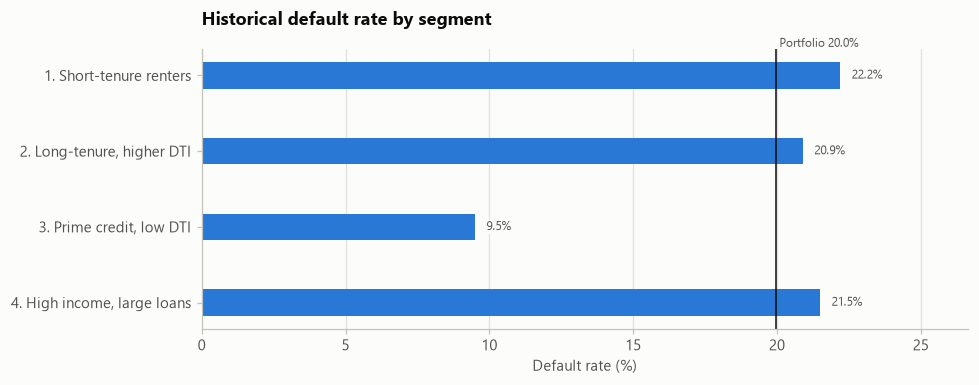

In [3]:
chart_table = segment_rates.set_index(
    segment_rates.index.map(segment_labels))

fig, ax = plt.subplots(figsize=(9, 3.6))
plot_default_rates(chart_table, "Historical default rate by segment", ax,
                   overall_rate)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_default_rate_by_segment.png")
plt.show()

**How to read the output.**
- **Prime credit, low DTI** stands apart: **9.5%** default, less than half the portfolio rate (lift **0.47**).
- The other three segments sit above the portfolio average (20.0%): **Short-tenure renters 22.2%** (lift 1.11), **High income, large loans 21.5%** (1.08) and **Long-tenure, higher DTI 20.9%** (1.04).
- **The surprise:** *High income, large loans* has the highest income of all segments, yet the second-highest default rate. Its large loans (median \$25,000) cancel out the benefit of a high income. The EDA showed the same pattern for single features: loans of \$30K or more defaulted 24.2% of the time.

**Check your prediction** from the notebook 04 exercise: how close was your ranking?

## 8.2 Are the differences real?

With hundreds of thousands of loans per segment, we can test whether the differences could be chance.
- **Chi-square test:** compares the default counts we observed in each segment with the counts we would expect if every segment had the portfolio rate. A tiny p-value means the differences are not chance.
- **Cramér's V:** measures how *strong* the link between segment and default is, from 0 (none) to 1 (perfect). Around 0.1 is usually called weak.
- **95% confidence interval** of each rate: the range in which the true rate very probably lies.

In [4]:
test = association_test(loans, "segment")
p_text = ("< 0.001" if test["p_value"] < 0.001
          else f"{test['p_value']:.3f}")
print(f"Chi-square = {test['chi_square']:,.0f} "
      f"({test['degrees_of_freedom']} degrees of freedom), p-value {p_text}")
print(f"Cramér's V = {test['cramers_v']:.3f}")
segment_rates[["name", "loans", "default_rate", "ci_low", "ci_high"]]

Chi-square = 13,854 (3 degrees of freedom), p-value < 0.001
Cramér's V = 0.101


,name,loans,default_rate,ci_low,ci_high
segment,,,,,
1,Short-tenure renters,443419,22.2,22.05,22.29
2,"Long-tenure, higher DTI",434783,20.9,20.74,20.99
3,"Prime credit, low DTI",171515,9.5,9.31,9.59
4,"High income, large loans",297964,21.5,21.33,21.63


**How to read the output.**
- The chi-square of about **13,850** gives a p-value below 0.001: the default rates really differ between segments.
- Each 95% interval is only about **±0.1 points** wide, and none of them overlap. Even the small gap between High income, large loans (21.5%) and Long-tenure, higher DTI (20.9%) is real.
- But **Cramér's V is only 0.10**. Knowing a borrower's segment tells us something about default risk, but far from everything. With 1.35 million loans almost any difference is "significant", so the *size* of the difference (lift, Cramér's V) matters more than the p-value.

## 8.3 Do the segments separate risk better than single features?

Notebook 02 measured how far default rates spread across the groups of single features. We add the segments to that comparison.

In [5]:
eda_rates = pd.read_csv(EDA_RATES_FILE)
spreads = eda_rates.groupby("feature")["default_rate"].agg(
    lowest="min", highest="max")
spreads.loc["SEGMENT (K-Means, k = 4)"] = [
    segment_rates["default_rate"].min(), segment_rates["default_rate"].max()]
spreads["spread_points"] = spreads["highest"] - spreads["lowest"]
spreads.sort_values("spread_points", ascending=False,
                    kind="stable").round(1)

,lowest,highest,spread_points
feature,,,
purpose,12.4,29.9,17.5
FICO score,8.3,25.3,17.0
DTI (%),14.8,30.7,15.9
state,13.2,26.1,12.9
issue year,13.7,26.4,12.7
"SEGMENT (K-Means, k = 4)",9.5,22.2,12.7
Loan amount,15.5,24.2,8.7
Annual income,15.1,23.6,8.5
employment length,18.8,27.0,8.2


**How to read the output.** The segments spread default rates by **12.7 points**: less than loan purpose (17.5), FICO score (17.0) or DTI (15.9), and about the same as state or issue year.

That is expected, and it is not a weakness. The segments were built **without `Default`**, to describe *who* the borrowers are, using several features at once. Sometimes those features pull in opposite directions (high income lowers risk, a large loan raises it). A model built to rank risk would need `Default` as its target (supervised learning), which is outside this project. The segments answer a different question: *what kinds of borrowers are in the portfolio, and how do their outcomes differ?*

## 8.4 Does the credit score still matter inside each segment?

In [6]:
loans["fico_band"] = pd.cut(loans["fico_n"], FICO_BINS, labels=FICO_LABELS,
                            right=False)
fico_by_segment = rate_pivot(loans, "segment", "fico_band")
fico_by_segment.index = fico_by_segment.index.map(segment_labels)
fico_by_segment.round(1)

fico_band,<680,680-699,700-719,720-739,740-759,760+
segment,,,,,,
1. Short-tenure renters,25.4,21.7,17.9,15.3,15.1,NaN
"2. Long-tenure, higher DTI",23.9,20.3,16.8,15.3,16.7,NaN
"3. Prime credit, low DTI",NaN,NaN,10.7,10.8,10.2,8.1
"4. High income, large loans",28.4,22.9,17.8,15.0,13.0,13.2


**How to read the output.** Each cell is the default rate (%) of one segment and FICO band. Cells with fewer than 1,000 loans are left empty (NaN) because their rates would be unreliable.
- In segments 1, 2 and 4, **FICO still separates risk strongly**. In *High income, large loans*, the rate falls from **28.4%** (FICO below 680) to **13.0%** (740–759).
- *Prime credit, low DTI* contains almost no loans below FICO 700 (its first two cells are empty), and its rates stay low in every band (8.1–10.8%).

**Lesson:** segments and credit scores are **complementary**. A lender would use the segment to understand and serve a borrower group, and the credit score to price individual risk.

## 8.5 Trends: default rates and segment mix by issue year

The **Portfolio Trend Monitoring** use case. We show 2010–2018, the years in which every segment has at least 1,000 loans.

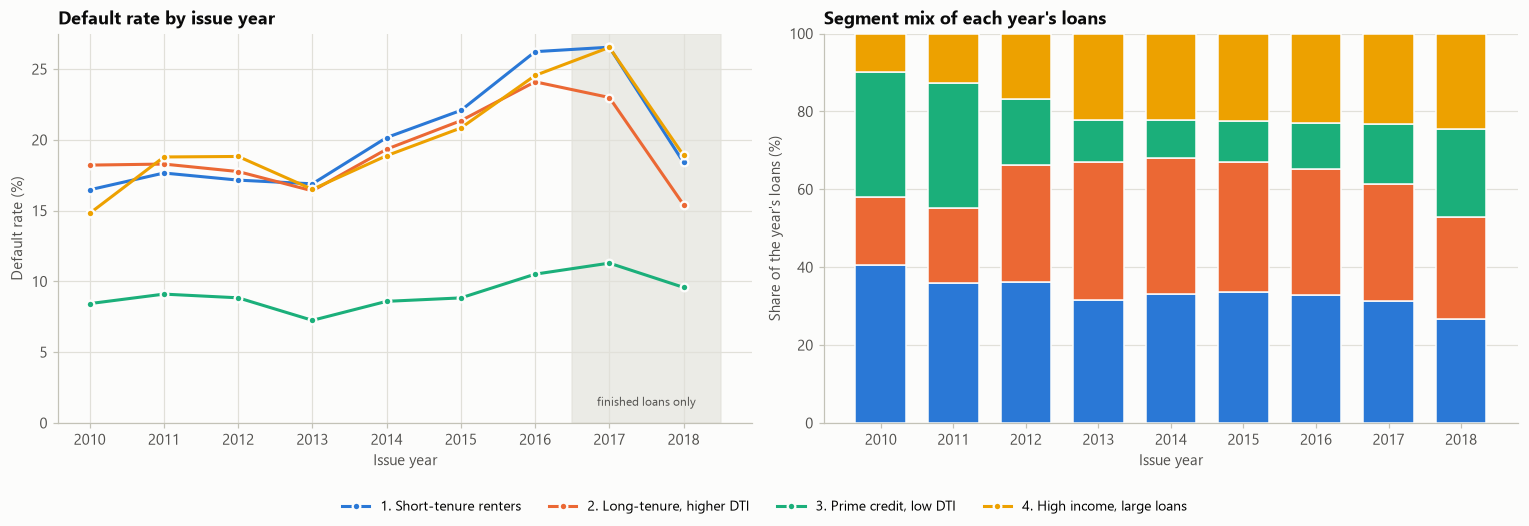

segment,1,2,3,4
issue_year,,,,
2010,16.5,18.2,8.4,14.8
2011,17.7,18.3,9.1,18.8
2012,17.2,17.8,8.8,18.8
2013,16.9,16.4,7.2,16.5
2014,20.2,19.3,8.6,18.9
2015,22.1,21.4,8.8,20.8
2016,26.2,24.1,10.5,24.5
2017,26.5,23.0,11.3,26.5
2018,18.4,15.4,9.6,18.9


In [7]:
years = list(range(2010, 2019))
recent = loans[loans["issue_year"].isin(years)]
year_rates = rate_pivot(recent, "issue_year", "segment")
year_mix = 100 * pd.crosstab(recent["issue_year"], recent["segment"],
                             normalize="index")

fig, (ax_rate, ax_mix) = plt.subplots(1, 2, figsize=(14, 4.8))
for segment, color in zip(year_rates.columns, SEGMENT_COLORS):
    ax_rate.plot(year_rates.index, year_rates[segment], color=color,
                 marker="o", markersize=5, markeredgecolor=SURFACE,
                 markeredgewidth=1.5, label=segment_labels[segment])
ax_rate.axvspan(2016.5, 2018.5, color=GRID, alpha=0.6, zorder=0)
ax_rate.text(2017.5, 1, "finished loans only", ha="center", va="bottom",
             fontsize=8, color=TEXT_SECONDARY)
ax_rate.set_title("Default rate by issue year")
ax_rate.set_ylabel("Default rate (%)")
ax_rate.set_ylim(0, None)

bottom = np.zeros(len(year_mix))
for segment, color in zip(year_mix.columns, SEGMENT_COLORS):
    ax_mix.bar(year_mix.index, year_mix[segment], bottom=bottom, width=0.7,
               color=color, edgecolor=SURFACE, linewidth=1,
               label=segment_labels[segment])
    bottom += year_mix[segment].to_numpy()
ax_mix.set_title("Segment mix of each year's loans")
ax_mix.set_ylabel("Share of the year's loans (%)")
ax_mix.set_ylim(0, 100)
ax_mix.grid(axis="x", visible=False)

for ax in (ax_rate, ax_mix):
    ax.set_xticks(years)
    ax.set_xlabel("Issue year")
# One legend for both charts: the colours mean the same segment in each.
handles, labels = ax_rate.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIGURES_DIR / "05_trends_by_year.png")
plt.show()
year_rates.round(1)

**How to read the charts.**
- **The ranking is stable.** *Prime credit, low DTI* has the lowest default rate in **every** year (7.2–11.3%), far below the other three segments.
- **The other three move together:** lowest for loans issued in **2013** (16.4–16.9%), highest in **2016–2017** (23.0–26.5%).
- **The rise after 2013 happened inside every segment.** It is not only a change in who was borrowing; loans issued in those years simply did worse within each type of borrower.
- **The mix changed too.** *Prime credit* made up about a third of each year's loans in 2010–2011 (32%), but only about 10% in 2013–2015, while *Long-tenure, higher DTI* and *High income, large loans* grew.
- **Caution (grey band):** 2017–2018 contain only loans that had already finished when the data was collected, so those years are biased (notebook 02).

## 8.6 Geography: the ten largest states

The **Geographic Portfolio Analysis** use case: default rate (%) per segment in the ten states with the most loans, plus all segments together.

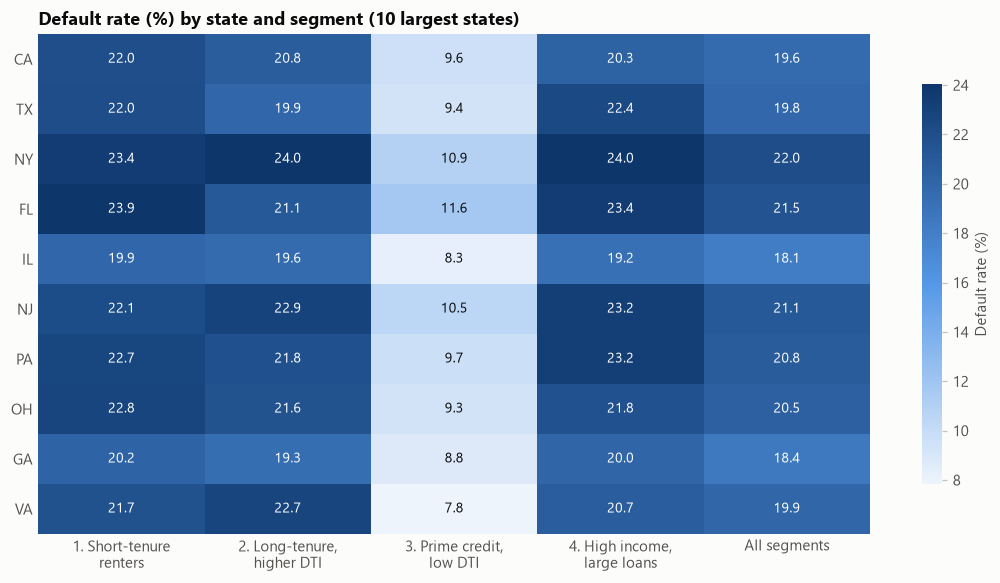

In [8]:
top_states = loans["addr_state"].value_counts().index[:10]
in_top = loans[loans["addr_state"].isin(top_states)]
state_rates = rate_pivot(in_top, "addr_state", "segment")
state_rates["All segments"] = (
    in_top.groupby("addr_state", observed=True)[TARGET_COLUMN].mean() * 100)
state_rates = state_rates.loc[list(top_states)]
state_rates.columns = [textwrap.fill(segment_labels.get(column, column), 16)
                       for column in state_rates.columns]

fig, ax = plt.subplots(figsize=(10, 5.4))
image = plot_rate_heatmap(ax, state_rates,
                          "Default rate (%) by state and segment "
                          "(10 largest states)")
colour_bar = fig.colorbar(image, ax=ax, shrink=0.8)
colour_bar.set_label("Default rate (%)")
colour_bar.outline.set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_state_segment_heatmap.png")
plt.show()

**How to read the heatmap.** Rows are the ten largest states (most loans at the top); darker cells mean higher default rates.
- *Prime credit, low DTI* is the lightest column in **every** state (7.8% in Virginia to 11.6% in Florida). The segment pattern holds everywhere.
- **States still differ inside segments.** New York and Florida are darker than average in most columns, while Illinois and Georgia are lighter. Location adds information beyond the segments.
- **Use with care:** location can be linked to protected characteristics, so state belongs in portfolio *monitoring* (where are losses concentrated?), not in decisions about individual applicants. This is also why `addr_state` was never a clustering feature.

## 8.7 Default rates across the three algorithms

The **Default Rate Comparison** metric applied to the **Clustering Algorithm Comparison**: on the shared 10,000-loan sample from notebook 04, how different are the default rates of the groups each algorithm found?

In [9]:
cluster_sample = pd.read_pickle(CLUSTER_SAMPLE_FILE)
positions = cluster_sample["position"].to_numpy()
sample_loans = pd.concat(
    [loans[[TARGET_COLUMN]].iloc[positions].reset_index(drop=True),
     cluster_sample.drop(columns="position")], axis=1)

algorithm_rows = []
for column, algorithm in [("kmeans_segment", "K-Means"),
                          ("ward_cluster", "Hierarchical (Ward)"),
                          ("dbscan_label", "DBSCAN")]:
    table = default_rate_table(sample_loans, column)
    rates = table["default_rate"]
    names = {group: ("noise" if group == NOISE
                     else "cluster" if column == "dbscan_label" else group)
             for group in rates.index}
    group_text = ", ".join(
        f"{names[group]}: {rate:.1f}% ({table.loc[group, 'loans']:,} loans)"
        for group, rate in rates.items())
    algorithm_rows.append({"algorithm": algorithm, "groups": len(table),
                           "lowest_%": rates.min(), "highest_%": rates.max(),
                           "spread_points": rates.max() - rates.min(),
                           "default rate by group": group_text})
algorithm_rates = pd.DataFrame(algorithm_rows).set_index("algorithm")
algorithm_rates.round(1)

,groups,lowest_%,highest_%,spread_points,default rate by group
algorithm,,,,,
K-Means,4,9.1,22.7,13.6,"1: 22.7% (3,299 loans), 2: 20.9% (3,219 loans)..."
Hierarchical (Ward),4,10.2,22.5,12.3,"1: 22.5% (3,332 loans), 2: 20.8% (2,372 loans)..."
DBSCAN,2,9.1,20.1,11.0,"noise: 9.1% (77 loans), cluster: 20.1% (9,923 ..."


**How to read the output.**
- **K-Means** (9.1–22.7%, spread 13.6 points) and **Ward** (10.2–22.5%, spread 12.3 points) show the same risk pattern: one prime group at about 10% and three groups at about 21–23%. The two algorithms broadly agree on the segments (73% in notebook 04), and they agree on the outcomes too.
- The sample rates differ a little from the all-loan rates in 8.1 (for example, 9.1% vs 9.5% for the prime segment), because a 10,000-loan sample carries sampling noise of about ±1.5 points per group.
- **DBSCAN** has a single cluster (20.1%), so it offers no segment comparison. Its 77 **noise** loans defaulted only 9.1% of the time, but with so few loans that rate could easily be several points off. Section 9 studies these unusual profiles on all loans.

## 8.8 Business insights by segment

All suggestions apply to **segments as a whole**. Belonging to a segment is not a judgement about any individual borrower (project ethics guideline).

| Segment | Share | Default rate (lift) | Who they are | Suggested segment-level actions |
|---|---|---|---|---|
| **1. Short-tenure renters** | 32.9% | 22.2% (1.11) | Lowest income (\$48.6K), smallest loans, 2.4 years in the current job, 61% rent | The highest-risk group: stronger affordability and employment checks, smaller first loans or credit-builder products, closer early monitoring |
| **2. Long-tenure, higher DTI** | 32.3% | 20.9% (1.04) | Longest employment (9.2 years), highest DTI (19.4%), FICO 686 | Risk tracks debt load: debt-consolidation products with DTI limits and payment-to-income checks |
| **3. Prime credit, low DTI** | 12.7% | 9.5% (0.47) | Mean FICO 758, lowest DTI (13.6%) | The lowest-risk group: retain and grow with preferential rates, pre-approved offers and faster approval (*personalised loan product design*) |
| **4. High income, large loans** | 22.1% | 21.5% (1.08) | Highest income (\$109K), largest loans (\$25,000), 67% mortgage | High income does not offset large loans: loan-to-income limits, verification of self-declared income, extra review of the largest loans |

**Portfolio view:** the three non-prime segments hold about 87% of the loans and all default above the average, so the portfolio's risk is spread widely rather than concentrated in one niche. Growing the share of prime-like borrowers would lower the overall default rate, and the trend chart shows that share fell sharply after 2011.

---
# Stage 9 — Anomaly Detection

**Concept.** An **anomaly** is a loan whose profile is rare compared with the rest of the portfolio. The PDF asks for two lenses:
1. **Density-based:** a loan that sits in a sparse region of the feature space, far from the dense crowd. DBSCAN calls these loans **noise**.
2. **Feature-level:** a loan with a value (or a simple ratio) far outside the normal range of one feature, for example a loan worth more than half the borrower's annual income.

**Why it matters.** Unusual profiles deserve a second look. They can be data-entry errors (an income typed with an extra zero), possible fraud, or simply rare but genuine cases that need special handling. An anomaly flag means **"review"**, never "reject".

## 9.1 Density-based anomalies: DBSCAN noise, extended to all loans

In notebook 04, DBSCAN on the 10,000-loan sample labelled 77 loans as noise. To apply the same idea to **all 1.35 million loans**, we use DBSCAN's own rule: a loan belongs to a cluster if it lies within `eps` of a **core point**, and otherwise it is noise. So we fit DBSCAN on the sample again (same settings, same `eps` from the k-distance knee), keep its core points, and measure every loan's distance to the nearest one (`density_distance()` in `src/anomalies.py`).

In [10]:
features = np.load(PCA_FEATURES_FILE)
sample_features = features[positions]

# The same eps as notebook 04: the knee of the k-distance curve.
k_distances = k_distance_curve(sample_features, DBSCAN_MIN_SAMPLES)
eps = round(float(k_distances[find_knee(k_distances)]), 2)

start = time.time()
distances, sample_dbscan = density_distance(features, positions, eps)
density_anomaly = distances > eps
print(f"eps = {eps} | distances for {len(distances):,} loans "
      f"in {time.time() - start:.0f} s")

# Check 1: the refitted DBSCAN finds the same noise loans as notebook 04.
same_noise = np.array_equal(sample_dbscan.labels_ == NOISE,
                            cluster_sample["dbscan_label"].to_numpy() == NOISE)
print(f"Same noise loans as notebook 04: {same_noise}")

# Check 2: on the sample, the rule flags exactly DBSCAN's noise loans.
sample_noise = sample_dbscan.labels_ == NOISE
flagged_in_sample = density_anomaly[positions]
noise_flagged = flagged_in_sample[sample_noise].mean()
cluster_flagged = flagged_in_sample[~sample_noise].mean()
print(f"Sample noise loans flagged: {noise_flagged:.0%} | "
      f"sample cluster loans flagged: {cluster_flagged:.0%}")
print(f"Density-based anomalies: {density_anomaly.sum():,} loans "
      f"({density_anomaly.mean():.2%} of the portfolio)")

eps = 1.46 | distances for 1,347,681 loans in 37 s
Same noise loans as notebook 04: True
Sample noise loans flagged: 100% | sample cluster loans flagged: 0%
Density-based anomalies: 10,731 loans (0.80% of the portfolio)


**How to read the output.** The two checks prove that the extension is faithful: the refitted DBSCAN finds the same 77 noise loans, and the distance rule flags 100% of them and 0% of the clustered sample loans. Applied to every loan, the rule flags **10,731 loans (0.80%)**, almost the same share as in the sample (0.77%). It needs only one nearest-neighbour search instead of running DBSCAN on 1.35 million loans.

### Who are the density-based anomalies?

In [11]:
profile_columns = {"revenue": "median income ($)",
                   "loan_amnt": "median loan ($)",
                   "fico_n": "median FICO",
                   "dti_n": "median DTI (%)",
                   "emp_length_years": "median employment years"}


def describe_group(mask):
    """Medians and a few shares for the loans selected by `mask`."""
    group = loans.loc[mask]
    values = group[list(profile_columns)].median().rename(profile_columns)
    high_income = group["revenue"] > 250_000
    values["income above $250K (%)"] = 100 * high_income.mean()
    values["in segment 3 or 4 (%)"] = (
        100 * group["segment"].isin([3, 4]).mean())
    values["default rate (%)"] = 100 * group[TARGET_COLUMN].mean()
    return values


pd.DataFrame({"density anomalies": describe_group(density_anomaly),
              "all other loans": describe_group(~density_anomaly)}).round(1)

,density anomalies,all other loans
median income ($),168000.0,65000.0
median loan ($),24000.0,12000.0
median FICO,782.0,692.0
median DTI (%),9.2,17.7
median employment years,5.0,6.0
income above $250K (%),37.2,0.8
in segment 3 or 4 (%),95.4,34.3
default rate (%),13.7,20.0


**How to read the output.** The density-based anomalies are mostly **very wealthy, prime borrowers**:
- median income **\$168,000** (vs \$65,000), median FICO **782** (vs 692) and median DTI **9.2%** (vs 17.7%);
- **37%** declare an income above \$250,000, compared with under 1% of other loans;
- **95.4%** belong to the *Prime credit* or *High income* segments.

They defaulted **less** often (13.7% vs 20.0%). Being unusual is not the same as being risky: these loans are isolated because few borrowers combine such high incomes with such clean credit.

## 9.2 Feature-level anomalies: five simple rules

Each rule looks at one feature (or one ratio), so it is easy to explain to a credit officer:

| Rule | Threshold | Why it is unusual |
|---|---|---|
| Very high income | top 0.1% of incomes | self-declared income far above normal: worth verifying |
| Very low income | bottom 0.1% of incomes | can the borrower afford any loan? |
| Loan > 50% of annual income | loan ÷ income > 0.5 | a very large loan for the income (loans normally stay below about 37%: the 90th percentile) |
| DTI above 50% | `dti_n` > 50 | more than half of the income already goes to debt payments |
| DTI recorded as 999 | the raw code 999 (set to missing in notebook 01) | a data-quality problem |

In [12]:
flags, thresholds = feature_anomaly_flags(loans)
rule_table = anomaly_summary(loans, flags)
rule_table.insert(0, "rule", [RULE_LABELS[name] for name in rule_table.index])
rule_table.insert(1, "threshold",
                  [thresholds[name] for name in rule_table.index])
rule_table["also_density_anomaly_%"] = [
    100 * (flags[name].to_numpy() & density_anomaly).sum()
    / flags[name].sum() for name in rule_table.index]

feature_anomaly = flags.any(axis=1).to_numpy()
print(f"Flagged by at least one rule: {feature_anomaly.sum():,} loans "
      f"({feature_anomaly.mean():.2%}), default rate "
      f"{100 * loans.loc[feature_anomaly, TARGET_COLUMN].mean():.1f}%")
rule_table.round(2)

Flagged by at least one rule: 8,369 loans (0.62%), default rate 27.2%


,rule,threshold,loans,share_%,default_rate_%,lift,also_density_anomaly_%
flag,,,,,,,
very_high_income,Very high income (top 0.1%),"income >= $585,000",1351,0.10,12.36,0.62,88.30
very_low_income,Very low income (bottom 0.1%),"income <= $10,800",1364,0.10,26.17,1.31,23.39
loan_over_half_income,Loan > 50% of annual income,loan / income > 0.5,2923,0.22,32.98,1.65,10.43
dti_over_50,DTI above 50%,DTI > 50%,2742,0.20,28.81,1.44,10.90
dti_code_999,DTI recorded as 999 (unknown),DTI was 999 in the raw data,38,0.00,23.68,1.19,0.00


**How to read the output.**
- **Loan > 50% of annual income** is the strongest warning sign: **33.0%** default, lift **1.65**.
- **DTI above 50%** (28.8%, lift 1.44) and **very low income** (26.2%, lift 1.31) are also clearly riskier.
- **Very high income** is the opposite: **12.4%** default (lift 0.62). These loans are mostly the same wealthy borrowers the density lens found (see the last column).
- The **38 loans with DTI code 999** are a data-quality issue rather than a risk signal; they were set to missing in notebook 01 and imputed with the median before clustering.
- Altogether **8,369 loans (0.62%)** break at least one rule, and they defaulted **27.2%** of the time.

## 9.3 Two lenses, two kinds of unusual

In [13]:
lens_group = np.select(
    [density_anomaly & feature_anomaly, density_anomaly, feature_anomaly],
    ["both lenses", "density-based only", "feature-level only"],
    default="not flagged")
lens_table = default_rate_table(loans.assign(anomaly_group=lens_group),
                                "anomaly_group")
lens_table.loc[["not flagged", "density-based only", "both lenses",
                "feature-level only"]]

,loans,defaults,default_rate,lift
anomaly_group,,,,
not flagged,1330663,265871,20.0,1.00
density-based only,8649,1104,12.8,0.64
both lenses,2082,365,17.5,0.88
feature-level only,6287,1909,30.4,1.52


**How to read the output.** The two lenses find **different kinds of unusual**:
- **Density-based only (8,649 loans): 12.8% default.** Wealthy, prime borrowers in a sparse corner of the feature space: rare, but *safer* than average.
- **Feature-level only (6,287 loans): 30.4% default.** *Stretched* borrowers with large loans or heavy debt for their income. They sit inside the dense crowd in the 7 PCA dimensions, so only the rules catch them, and they are much riskier.
- **Both lenses (2,082 loans): 17.5% default.** Mostly extreme incomes, which both lenses notice.

This is why the PDF asks for both: density-based clustering finds *rare combinations*, while feature-level rules find *specific warning signs*. Neither alone tells the whole story.

## 9.4 Picture: where the anomalies sit

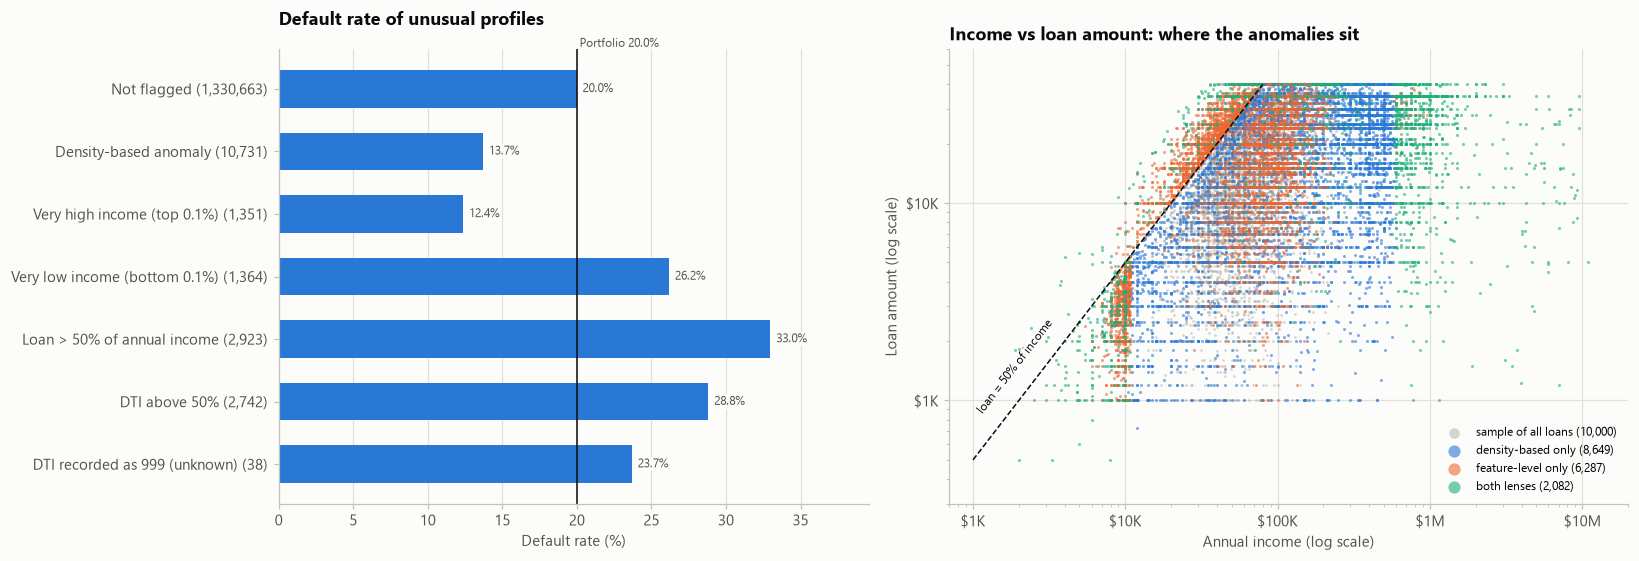

In [14]:
rate_rows = {"Not flagged": ~(density_anomaly | feature_anomaly),
             "Density-based anomaly": density_anomaly}
rate_rows.update({RULE_LABELS[name]: flags[name].to_numpy()
                  for name in flags.columns})
bar_table = pd.DataFrame({"default_rate": {
    f"{name} ({mask.sum():,})": 100 * loans.loc[mask, TARGET_COLUMN].mean()
    for name, mask in rate_rows.items()}})

fig, (ax_rates, ax_map) = plt.subplots(
    1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
plot_default_rates(bar_table, "Default rate of unusual profiles", ax_rates,
                   overall_rate)

background = loans.iloc[positions]
ax_map.scatter(background["revenue"], background["loan_amnt"], s=3,
               color=TEXT_MUTED, alpha=0.35, linewidths=0,
               label=f"sample of all loans ({len(background):,})")
for mask, color, label in [
        (density_anomaly & ~feature_anomaly, SERIES_COLORS[0],
         "density-based only"),
        (feature_anomaly & ~density_anomaly, SERIES_COLORS[1],
         "feature-level only"),
        (density_anomaly & feature_anomaly, SERIES_COLORS[2],
         "both lenses")]:
    ax_map.scatter(loans.loc[mask, "revenue"], loans.loc[mask, "loan_amnt"],
                   s=4, color=color, alpha=0.6, linewidths=0,
                   label=f"{label} ({mask.sum():,})")
income_line = np.array([1_000, 80_000])
ax_map.plot(income_line, 0.5 * income_line, color=TEXT_PRIMARY,
            linestyle="--", linewidth=1)
ax_map.set_xscale("log")
ax_map.set_yscale("log")
ax_map.set_xlim(700, 2e7)
ax_map.set_ylim(300, 60_000)
ax_map.xaxis.set_major_formatter(DOLLAR_FORMATTER)
ax_map.yaxis.set_major_formatter(DOLLAR_FORMATTER)
ax_map.set_xlabel("Annual income (log scale)")
ax_map.set_ylabel("Loan amount (log scale)")
ax_map.set_title("Income vs loan amount: where the anomalies sit")
ax_map.legend(loc="lower right", fontsize=8, markerscale=4)
fig.tight_layout()

# Write the line's label at the same angle as the line on screen.
start_xy, end_xy = ax_map.transData.transform([(1_000, 500),
                                               (80_000, 40_000)])
angle = np.degrees(np.arctan2(end_xy[1] - start_xy[1],
                              end_xy[0] - start_xy[0]))
ax_map.text(1_150, 850, "loan = 50% of income", rotation=angle,
            rotation_mode="anchor", fontsize=8, color=TEXT_PRIMARY)
fig.savefig(FIGURES_DIR / "05_anomalies.png")
plt.show()

**How to read the charts.**
- **Left:** default rate for each kind of anomaly, with the portfolio average as a vertical line. The rules about large loans, heavy debt and low income sit to the right of the line (riskier); very high income and density-based anomalies sit to the left (safer).
- **Right:** each dot is a loan, with income and loan amount on log scales. The grey cloud is the normal portfolio. Density-based anomalies (blue) lean to the **right**: half of them earn more than \$150,000, above the portfolio's 90th percentile. Those inside the cloud are unusual through features this picture cannot show, mainly a very high FICO combined with a very low DTI. Feature-level anomalies (orange) sit **above the dashed line**, where the loan is more than half the income, and at the **far left** (very low incomes); the orange dots inside the cloud are loans flagged for DTI above 50%, which this picture cannot show. Both lenses together (aqua) are mostly the most extreme incomes.

## 9.5 The most isolated loans: examples to investigate

The five loans furthest from any dense region. `id` and location are left out on purpose: the point is the *pattern*, not the person.

In [15]:
most_isolated = np.argsort(distances)[::-1][:5]
example_columns = ["revenue", "loan_amnt", "fico_n", "dti_n",
                   "emp_length_years", "home_ownership_n", "purpose",
                   "segment"]
examples = loans.iloc[most_isolated][example_columns].reset_index(drop=True)
examples["distance_to_dense_region"] = distances[most_isolated].round(2)
examples

,revenue,loan_amnt,fico_n,dti_n,emp_length_years,home_ownership_n,purpose,segment,distance_to_dense_region
0,10999200.0,5000,687.0,0.07,1.0,RENT,major_purchase,4,7.17
1,9300000.0,8400,672.0,0.02,1.0,RENT,debt_consolidation,4,6.75
2,9225000.0,11600,667.0,0.11,8.0,RENT,car,4,6.32
3,8400000.0,30000,662.0,0.31,2.0,RENT,debt_consolidation,4,6.27
4,7000000.0,1200,687.0,0.14,10.0,RENT,major_purchase,4,6.24


**How to read the output.** All five declare incomes of about **\$7–11 million** but borrowed only **\$1,200–30,000**, all five rent, and their FICO scores (662–687) are ordinary. Their DTI is almost 0 because DTI is calculated from that same income. Such incomes may be genuine, but they are also what a mistyped income looks like (extra zeros), and Lending Club incomes are **self-declared**. A lender would check the income documents. For the analysis this matters too: the log transform and median-based profiles were chosen in notebooks 01–04 precisely so that a few such values could not distort the segments.

## 10. Save the results

In [16]:
# 1. Default rate, lift and confidence interval per segment (dashboard,
#    report).
segment_rates.round(3).to_csv(SEGMENT_DEFAULT_RATES_FILE)

# 2. Summary of every anomaly lens and rule (report).
all_flags = pd.concat(
    [pd.DataFrame({"density_based": density_anomaly}, index=loans.index),
     flags,
     pd.DataFrame({"any_feature_rule": feature_anomaly}, index=loans.index)],
    axis=1)
anomaly_summary(loans, all_flags).round(3).to_csv(ANOMALY_SUMMARY_FILE)

# 3. Every loan's anomaly flags (kept out of Git with the other data).
anomaly_table = pd.concat(
    [pd.DataFrame({ID_COLUMN: loans[ID_COLUMN].to_numpy(),
                   "segment": loans["segment"].to_numpy(),
                   "density_distance": distances.round(3)},
                  index=loans.index),
     all_flags], axis=1)
anomaly_table.to_pickle(ANOMALIES_FILE)

for path in [SEGMENT_DEFAULT_RATES_FILE, ANOMALY_SUMMARY_FILE,
             ANOMALIES_FILE]:
    print(f"Saved {path.parent.name}/{path.name} "
          f"({path.stat().st_size / 1024:,.1f} KB)")

Saved reports/segment_default_rates.csv (0.3 KB)
Saved reports/anomaly_summary.csv (0.3 KB)
Saved processed/anomalies.pkl (31,587.7 KB)


## Summary — Stages 8 and 9

| Step | Result |
|---|---|
| Default rate by segment | Prime credit, low DTI **9.5%** (lift 0.47) · Long-tenure, higher DTI 20.9% · High income, large loans 21.5% · Short-tenure renters **22.2%** (lift 1.11) |
| Are the differences real? | Yes: chi-square ≈ 13,850, p < 0.001, intervals ±0.1 points. But Cramér's V = 0.10: segment explains only part of default |
| Segments vs single features | Spread 12.7 points, below purpose, FICO and DTI. The segments describe borrowers; they are not a risk score |
| FICO inside segments | Still separates risk (e.g. 28.4% → 13.0% in High income, large loans): segment and score are complementary |
| Trends | Prime is lowest every year; the 2016–2017 rise happened inside every segment; prime's share fell from about 32% to about 10% |
| Geography | Segment pattern holds in all 10 largest states; states still differ inside segments; use state for monitoring only |
| Algorithms | K-Means and Ward show the same risk pattern; DBSCAN gives one cluster plus 77 noise loans |
| Density-based anomalies | **10,731 loans (0.80%)**, mostly wealthy prime borrowers, **13.7%** default |
| Feature-level anomalies | **8,369 loans (0.62%)**, **27.2%** default; loan > 50% of income is the strongest sign (33.0%) |
| Saved | `reports/segment_default_rates.csv`, `reports/anomaly_summary.csv`, `data/processed/anomalies.pkl`, 4 figures `05_*.png` |

**Next:** Stage 10 — the Streamlit dashboard (`app.py`), which brings the segments, profiles, default patterns and anomalies together.

---
## Your turn — exercise (about 10 minutes)

1. **Your prediction.** Compare your ranking from the notebook 04 exercise with section 8.1. Which segment surprised you, and what in its profile explains the result?
2. **Trend detective.** Did the overall default rate rise after 2013 because the *mix* of segments changed, or because loans did worse *within* segments? Give the evidence from section 8.5.
3. **Explain to a manager.** In two sentences, explain why a loan flagged as "loan > 50% of annual income" should be **reviewed** rather than automatically rejected.

## Progress check

- [ ] The notebook ran from top to bottom without errors (saved with **Ctrl+S**).
- [ ] `reports/figures` has 4 new `05_*.png` charts; `reports` has `segment_default_rates.csv` and `anomaly_summary.csv`.
- [ ] You can explain the default rate of each segment, why the segments spread risk less than FICO, and the two kinds of anomalies.
- [ ] Commit and push: `git add .` → `git commit -m "Stages 8-9: default patterns and anomaly detection"` → `git push`.

---
## Viva practice — Stages 8 and 9

**1. When did you first use the Default column with the segments, and why only then?**
Only in this notebook, after the segments had been saved in notebook 04 with `Default` dropped. Using it earlier could have shaped the segments around the outcome. The PDF asks us to compare default rates across clusters without using `Default` to form them.

**2. Which segment has the highest and the lowest default rate?**
Lowest: Prime credit, low DTI (9.5%, lift 0.47). Highest: Short-tenure renters (22.2%, lift 1.11), closely followed by High income, large loans (21.5%) and Long-tenure, higher DTI (20.9%). The portfolio average is 20.0%.

**3. Are those differences statistically significant?**
Yes: a chi-square test gives p < 0.001, and every segment's 95% confidence interval is only about ±0.1 points wide, with no overlaps. But Cramér's V is 0.10, a weak association, so segment membership explains only part of who defaults.

**4. Why do the segments separate risk less than FICO alone?**
They were built without `Default` to describe borrowers using several features at once, and some of those pull in opposite directions (high income vs large loans). Ranking risk is the job of a supervised model with `Default` as its target, which is outside this project's scope.

**5. Why does the high-income segment default more than average?**
Its loans are the largest in the portfolio (median \$25,000), and larger loans default more often (24.2% for loans of \$30K or more in the EDA). Income is also self-declared. A high income does not offset the bigger repayment burden.

**6. What is lift?**
A group's default rate divided by the portfolio rate: 1.11 means 11% more defaults than average; 0.47 means less than half.

**7. How did you detect density-based anomalies on all 1.35 million loans?**
With DBSCAN's own rule: a point within eps of a core point belongs to a cluster, otherwise it is noise. I fitted DBSCAN on the 10,000-loan sample (eps 1.46, min_samples 14), kept its core points, and flagged every loan further than eps from the nearest one. It reproduces the 77 sample noise points exactly and flags 10,731 loans (0.80%).

**8. Which feature-level rules did you use, and why?**
Very high and very low income (top and bottom 0.1%), loan above 50% of annual income, DTI above 50%, and DTI recorded as 999. Each looks at one feature or ratio, so a credit officer can understand and act on it.

**9. Are anomalies riskier?**
It depends on the kind. Density-based anomalies are mostly wealthy prime borrowers and default less (13.7%). Feature-level anomalies such as large loans for the income or heavy debt default much more (27.2% overall, 33.0% for loan > 50% of income). That is why both lenses are needed.

**10. How do you avoid unfair conclusions about individual borrowers?**
All actions are suggested for segments, not individuals; anomaly flags mean "review", not "reject"; examples are shown without id or location; and geography is used only for portfolio monitoring because it can be linked to protected characteristics.

**11. What did the trend analysis show?**
Prime credit has the lowest default rate in every year. The rise for loans issued in 2016–2017 happened inside every segment, so it was not just a change in mix, although prime's share of new loans also fell from about a third to about a tenth. 2017–2018 are biased because only finished loans are included.

**12. How did the algorithms compare on default rates?**
On the same 10,000 loans, K-Means and Ward produced the same risk pattern (one prime group at about 10%, three groups at 21–23%). DBSCAN gave one cluster at 20.1% plus 77 noise loans at 9.1%, so it adds anomaly information rather than segments.